[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/keyvanmahmoudi/Data_Science_Course/blob/main/notebooks/10_linear_algebra.ipynb)

<div dir="rtl">

# جلسه ۱۰: جبر خطی پایه برای علم داده

**اهداف این جلسه**

- بردار: جمع، ضرب عددی، طول (نُرم)، ضرب داخلی و **شباهت کسینوسی**
- ماتریس: ضرب ماتریسی و دیدن ماتریس به‌عنوان یک **تبدیل**
- ماتریس همانی، معکوس و دترمینان
- حل دستگاه معادلات خطی
- **کمترین مربعات**: برازش خط به داده با جبر خطی
- **مقدار ویژه و بردار ویژه**
- پیاده‌سازی **PCA** از صفر

در علم داده، هر جدول یک ماتریس است: هر سطر یک **بردار** (یک مشاهده) و هر ستون یک ویژگی. رگرسیون خطی، PCA، شبکه‌های عصبی و مدل‌های زبانی همه در نهایت ضرب و تجزیه‌ی ماتریس‌ها هستند.

</div>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
np.set_printoptions(precision=3, suppress=True)

<div dir="rtl">

## ۱. بردار

بردار فهرستی مرتب از اعداد است. از نظر هندسی، یک پیکان از مبدأ است؛ از نظر داده، یک سطر از جدول. مثلاً یک آپارتمان: `[متراژ، تعداد اتاق، سن بنا]`.

- **جمع** دو بردار: عنصربه‌عنصر
- **ضرب عددی**: کشیدن یا کوچک کردن بردار
- **نُرم** (طول): $\|v\| = \sqrt{v_1^2 + v_2^2 + \dots}$

</div>

u + v  = [4 3]
2 * u  = [6 2]
|u|    = 3.162


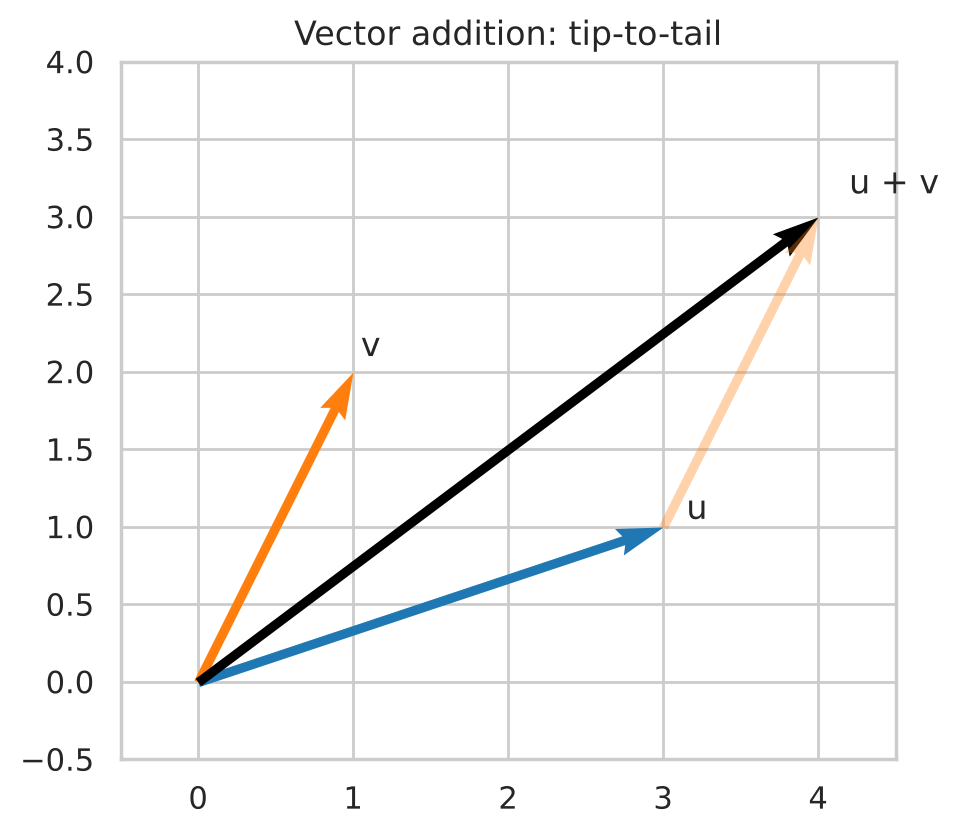

In [2]:
u = np.array([3, 1])
v = np.array([1, 2])
print("u + v  =", u + v)
print("2 * u  =", 2 * u)
print("|u|    =", np.linalg.norm(u).round(3))

fig, ax = plt.subplots(figsize=(5, 5))
for vec, color, label in [(u, "tab:blue", "u"), (v, "tab:orange", "v"), (u + v, "black", "u + v")]:
    ax.quiver(0, 0, *vec, angles="xy", scale_units="xy", scale=1, color=color, width=0.012)
    ax.text(*(vec * 1.05), label, fontsize=12)
ax.quiver(*u, *v, angles="xy", scale_units="xy", scale=1, color="tab:orange", alpha=0.35, width=0.012)
ax.set_xlim(-0.5, 4.5)
ax.set_ylim(-0.5, 4)
ax.set_aspect("equal")
ax.set_title("Vector addition: tip-to-tail")
plt.show()

<div dir="rtl">

## ۲. ضرب داخلی و شباهت کسینوسی

ضرب داخلی (dot product):

$$u \cdot v = \sum_i u_i v_i = \|u\|\,\|v\| \cos\theta$$

پس کسینوس زاویه‌ی بین دو بردار:

$$\cos\theta = \frac{u \cdot v}{\|u\|\,\|v\|}$$

این **شباهت کسینوسی** است: ۱ یعنی هم‌جهت، ۰ یعنی عمود (بی‌ربط)، ۱- یعنی خلاف جهت. نکته‌ی مهم: به **جهت** بردار حساس است، نه به طولش.

یکی از مهم‌ترین کاربردهایش در پردازش زبان طبیعی است: هر متن را به یک بردار تبدیل می‌کنیم و متن‌های مشابه، بردارهای هم‌جهت دارند. ساده‌ترین روش، شمردن تکرار هر کلمه است (Bag of Words):

</div>

In [3]:
docs = {
    "d1": "data science uses statistics and python",
    "d2": "python and statistics for data analysis",
    "d3": "the football match ended with a late goal",
    "d4": "statistics statistics statistics data data",
}
vocab = sorted({w for text in docs.values() for w in text.split()})
X = pd.DataFrame([[text.split().count(w) for w in vocab] for text in docs.values()],
                 index=docs.keys(), columns=vocab)
X

,a,analysis,and,data,ended,football,for,goal,late,match,python,science,statistics,the,uses,with
d1,0,0,1,1,0,0,0,0,0,0,1,1,1,0,1,0
d2,0,1,1,1,0,0,1,0,0,0,1,0,1,0,0,0
d3,1,0,0,0,1,1,0,1,1,1,0,0,0,1,0,1
d4,0,0,0,2,0,0,0,0,0,0,0,0,3,0,0,0


In [4]:
def cosine_similarity(a, b):
    return a @ b / (np.linalg.norm(a) * np.linalg.norm(b))

M = X.values
sim = pd.DataFrame([[cosine_similarity(M[i], M[j]) for j in range(len(M))] for i in range(len(M))],
                   index=X.index, columns=X.index)
sim.round(2)

,d1,d2,d3,d4
d1,1.00,0.67,0.0,0.57
d2,0.67,1.00,0.0,0.57
d3,0.00,0.00,1.0,0.00
d4,0.57,0.57,0.0,1.00


<div dir="rtl">

- `d1` و `d2` (هر دو درباره‌ی علم داده) شباهت بالایی دارند.
- `d3` (فوتبال) با بقیه شباهت صفر دارد؛ هیچ کلمه‌ی مشترکی ندارند.
- `d4` کوتاه است اما چون همان کلمات را تکرار کرده، به `d1` شبیه است؛ طول متن روی شباهت کسینوسی اثر ندارد.

مدل‌های زبانی امروزی به‌جای شمارش کلمه، **بردارهای معنایی (embedding)** چندصدبعدی می‌سازند، اما مقایسه‌ی آن‌ها همچنان با همین شباهت کسینوسی انجام می‌شود.

## ۳. ماتریس و ضرب ماتریسی

ضرب ماتریس $A$ با ابعاد $(m \times n)$ در $B$ با ابعاد $(n \times p)$، ماتریسی $(m \times p)$ می‌دهد که درایه‌ی $(i, j)$ آن ضرب داخلی سطر $i$ از $A$ و ستون $j$ از $B$ است. در NumPy از عملگر `@` استفاده می‌کنیم.

> `A * B` ضرب **عنصربه‌عنصر** است و `A @ B` ضرب **ماتریسی**. این دو را اشتباه نگیرید.

</div>

In [5]:
# 3 products (rows) x 2 cost components per unit (material, labour), thousand Toman
cost_per_unit = np.array([[50, 20],
                          [80, 35],
                          [30, 10]])
# units of each product ordered by 2 branches (columns)
units = np.array([[100, 40],
                  [ 20, 60],
                  [ 70, 10]])

total = units.T @ cost_per_unit         # (2 x 3) @ (3 x 2) -> (2 x 2)
pd.DataFrame(total, index=["branch 1", "branch 2"], columns=["material", "labour"])

,material,labour
branch 1,8700,3400
branch 2,7100,3000


In [6]:
A = np.array([[1, 2], [3, 4]])
B = np.array([[0, 1], [1, 0]])
print("A @ B =\n", A @ B)
print("B @ A =\n", B @ A)
print("A * B (element-wise) =\n", A * B)

A @ B =
 [[2 1]
 [4 3]]
B @ A =
 [[3 4]
 [1 2]]
A * B (element-wise) =
 [[0 2]
 [3 0]]


<div dir="rtl">

ضرب ماتریسی **جابه‌جایی‌پذیر نیست**: در حالت کلی $AB \neq BA$.

### ماتریس به‌عنوان تبدیل

ضرب یک ماتریس $2 \times 2$ در بردارهای صفحه، صفحه را **تبدیل** می‌کند: می‌چرخاند، می‌کشد، قرینه می‌کند یا می‌بُرد. ستون‌های ماتریس دقیقاً نشان می‌دهند بردارهای پایه‌ی $(1, 0)$ و $(0, 1)$ به کجا می‌روند.

</div>

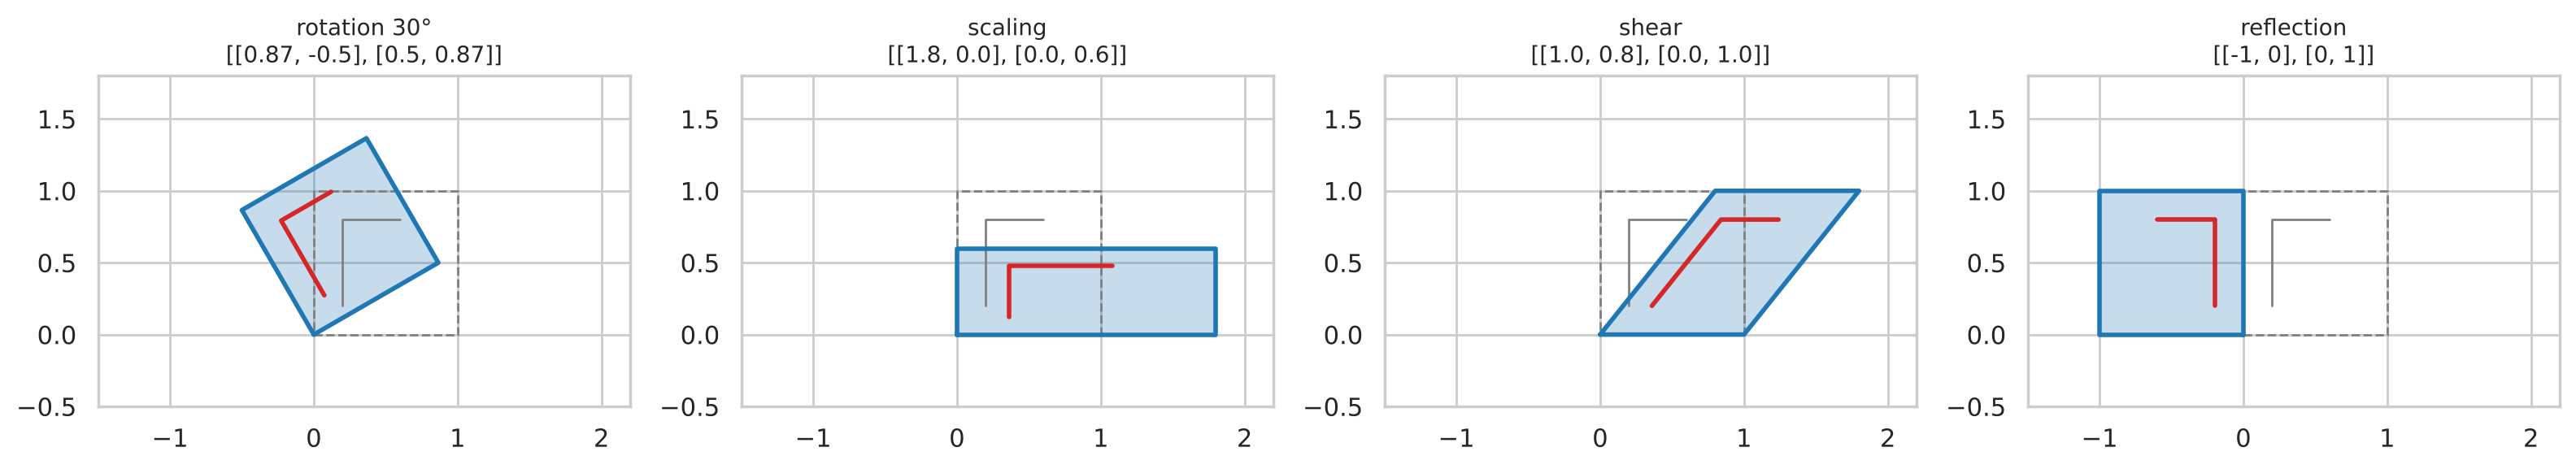

In [7]:
theta = np.deg2rad(30)
transforms = {
    "rotation 30°": np.array([[np.cos(theta), -np.sin(theta)], [np.sin(theta), np.cos(theta)]]),
    "scaling": np.array([[1.8, 0], [0, 0.6]]),
    "shear": np.array([[1, 0.8], [0, 1]]),
    "reflection": np.array([[-1, 0], [0, 1]]),
}
square = np.array([[0, 1, 1, 0, 0], [0, 0, 1, 1, 0]])          # corners as columns
letter = np.array([[0.2, 0.2, 0.6], [0.2, 0.8, 0.8]])           # a small "L" shape for orientation

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (name, T) in zip(axes, transforms.items()):
    ax.plot(*square, color="gray", linestyle="--", linewidth=1)
    ax.plot(*letter, color="gray", linewidth=1)
    ax.fill(*(T @ square), alpha=0.25, color="tab:blue")
    ax.plot(*(T @ square), color="tab:blue", linewidth=2)
    ax.plot(*(T @ letter), color="tab:red", linewidth=2)
    ax.set_title(f"{name}\n{np.round(T, 2).tolist()}", fontsize=10)
    ax.set_xlim(-1.5, 2.2)
    ax.set_ylim(-0.5, 1.8)
    ax.set_aspect("equal")
plt.tight_layout()
plt.show()

<div dir="rtl">

## ۴. همانی، معکوس و دترمینان

- **ماتریس همانی** $I$: هیچ تغییری نمی‌دهد، $AI = A$.
- **معکوس** $A^{-1}$: تبدیل را خنثی می‌کند، $A A^{-1} = I$.
- **دترمینان** $\det(A)$: ضریب تغییر مساحت (یا حجم) در تبدیل. اگر صفر باشد، تبدیل فضا را «له» می‌کند (مثلاً صفحه را روی یک خط می‌خواباند) و دیگر قابل برگشت نیست؛ یعنی ماتریس **معکوس ندارد** (ماتریس منفرد).

</div>

In [8]:
for name, T in transforms.items():
    print(f"{name:13s} det = {np.linalg.det(T):6.3f}")

S = transforms["shear"]
S_inv = np.linalg.inv(S)
print("\nshear inverse:\n", S_inv)
print("S @ S_inv:\n", S @ S_inv)

singular = np.array([[1, 2], [2, 4]])        # second column = 2 * first column
print("\ndet of singular matrix:", np.linalg.det(singular))

rotation 30°  det =  1.000
scaling       det =  1.080
shear         det =  1.000
reflection    det = -1.000

shear inverse:
 [[ 1.  -0.8]
 [ 0.   1. ]]
S @ S_inv:
 [[1. 0.]
 [0. 1.]]

det of singular matrix: 0.0


<div dir="rtl">

دوران مساحت را حفظ می‌کند (دترمینان ۱)، مقیاس‌بندی آن را ۱٫۰۸ برابر می‌کند و قرینه‌سازی جهت را برعکس می‌کند (دترمینان منفی). در ماتریس منفرد، یک ستون مضربی از دیگری است؛ در داده یعنی یک ویژگی کاملاً تکراری است (همان هم‌خطی که در جلسه‌ی ۶ بین `carat` و ابعاد الماس دیدیم).

## ۵. حل دستگاه معادلات خطی

یک کافه دو نوع بسته‌ی صبحانه می‌فروشد. دیروز ۳ بسته‌ی A و ۲ بسته‌ی B به قیمت کل ۸۴۰ هزار تومان، و امروز ۱ بسته‌ی A و ۴ بسته‌ی B به قیمت کل ۹۸۰ هزار تومان فروخته است. قیمت هر بسته چقدر است؟

$$\begin{cases} 3a + 2b = 840 \\ a + 4b = 980 \end{cases} \quad\Longrightarrow\quad \underbrace{\begin{bmatrix} 3 & 2 \\ 1 & 4 \end{bmatrix}}_{A} \begin{bmatrix} a \\ b \end{bmatrix} = \underbrace{\begin{bmatrix} 840 \\ 980 \end{bmatrix}}_{y}$$

</div>

In [9]:
A = np.array([[3, 2], [1, 4]])
y = np.array([840, 980])
solution = np.linalg.solve(A, y)
print("price of A and B (thousand Toman):", solution)
print("check A @ x == y:", np.allclose(A @ solution, y))

price of A and B (thousand Toman): [140. 210.]
check A @ x == y: True


<div dir="rtl">

> همیشه `np.linalg.solve` را به `np.linalg.inv(A) @ y` ترجیح دهید؛ هم سریع‌تر است و هم از نظر عددی پایدارتر.

## ۶. کمترین مربعات: وقتی جواب دقیق وجود ندارد

در داده‌ی واقعی، تعداد معادلات (مشاهدات) خیلی بیشتر از مجهولات است و هیچ خطی از همه‌ی نقاط نمی‌گذرد. به‌جای جواب دقیق، جوابی پیدا می‌کنیم که **مجموع مربعات خطا** را کمینه کند:

$$\hat{\beta} = \arg\min_\beta \|y - X\beta\|^2 \quad\Longrightarrow\quad X^\top X\, \hat{\beta} = X^\top y$$

این همان **رگرسیون خطی** است که در ترم بعد با scikit-learn می‌بینیم؛ اینجا آن را فقط با جبر خطی می‌سازیم. مثال: پیش‌بینی وزن پنگوئن از طول باله.

</div>

In [10]:
DATA_URL = "https://raw.githubusercontent.com/keyvanmahmoudi/Data_Science_Course/main/data/"
penguins = pd.read_csv(DATA_URL + "penguins.csv").dropna()

x = penguins["flipper_length_mm"].values
y = penguins["body_mass_g"].values
X = np.column_stack([np.ones_like(x), x])          # a column of ones for the intercept

beta_normal = np.linalg.solve(X.T @ X, X.T @ y)    # normal equations
beta_lstsq, *_ = np.linalg.lstsq(X, y, rcond=None) # numerically preferred
print("normal equations:", beta_normal)
print("np.linalg.lstsq :", beta_lstsq)

y_hat = X @ beta_lstsq
r2 = 1 - ((y - y_hat) ** 2).sum() / ((y - y.mean()) ** 2).sum()
print(f"body_mass = {beta_lstsq[0]:.1f} + {beta_lstsq[1]:.2f} * flipper_length,  R^2 = {r2:.3f}")

normal equations: [-5872.093    50.153]
np.linalg.lstsq : [-5872.093    50.153]
body_mass = -5872.1 + 50.15 * flipper_length,  R^2 = 0.762


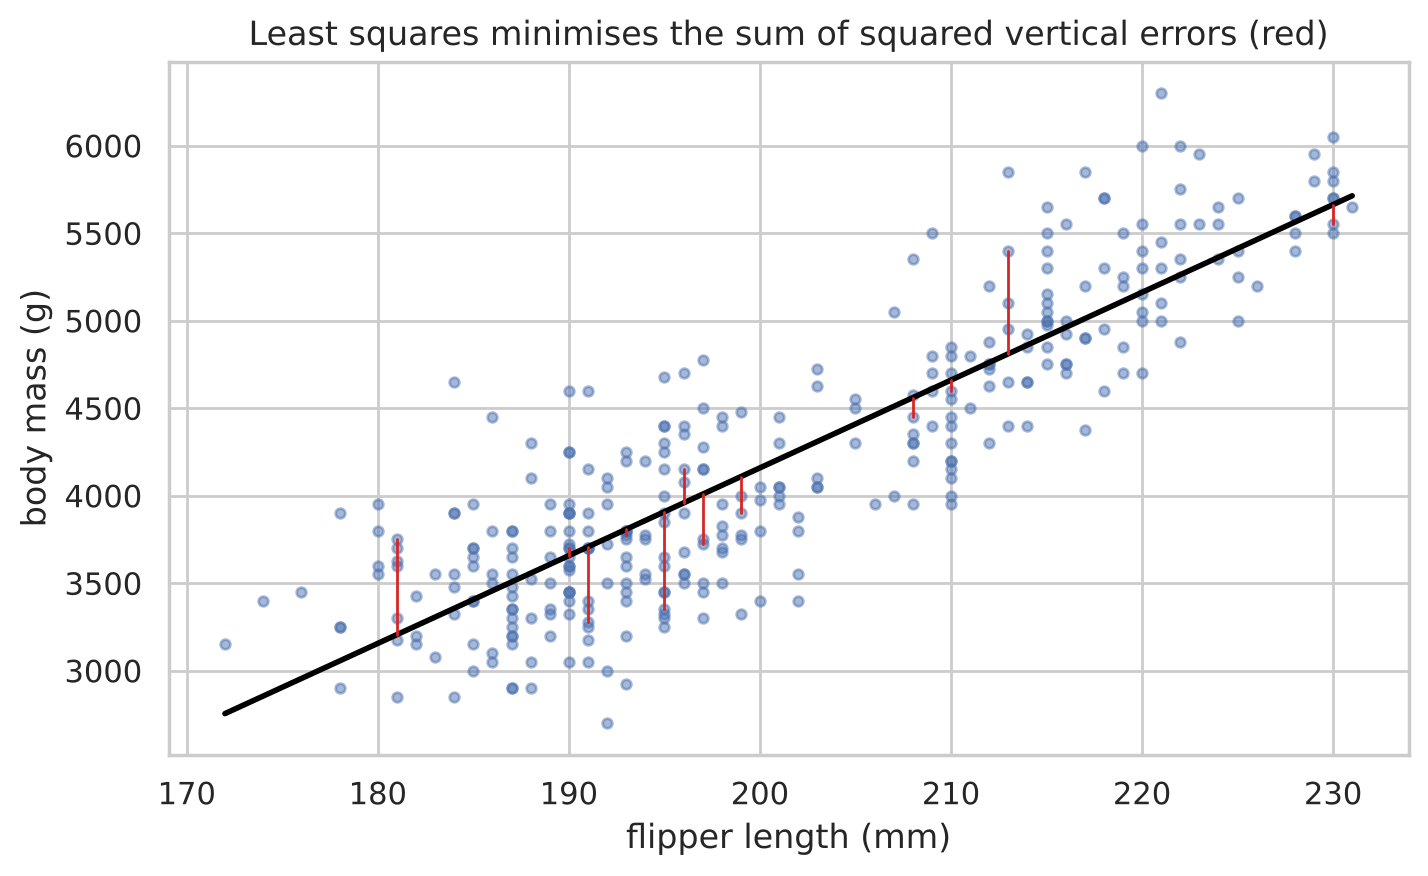

In [11]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(x, y, s=12, alpha=0.5)
order = np.argsort(x)
ax.plot(x[order], y_hat[order], color="black", linewidth=2)
idx = np.linspace(0, len(x) - 1, 12).astype(int)
for i in idx:
    ax.plot([x[i], x[i]], [y[i], y_hat[i]], color="tab:red", linewidth=1)
ax.set_xlabel("flipper length (mm)")
ax.set_ylabel("body mass (g)")
ax.set_title("Least squares minimises the sum of squared vertical errors (red)")
plt.show()

<div dir="rtl">

هر میلی‌متر طول باله بیشتر، به‌طور میانگین با حدود ۵۰ گرم وزن بیشتر همراه است و طول باله حدود ۷۶٪ تغییرات وزن را توضیح می‌دهد ($R^2$).

## ۷. مقدار ویژه و بردار ویژه

بیشتر بردارها در اثر یک تبدیل، **جهتشان** عوض می‌شود. اما برای هر ماتریس مربعی، جهت‌های خاصی وجود دارد که فقط کشیده یا کوچک می‌شوند و جهتشان ثابت می‌ماند:

$$A v = \lambda v$$

$v$ را **بردار ویژه** و $\lambda$ (ضریب کشیدگی) را **مقدار ویژه** می‌گویند. برای ماتریس‌های **متقارن** (مثل ماتریس کوواریانس) از `np.linalg.eigh` استفاده می‌کنیم که مقادیر ویژه را حقیقی و به ترتیب صعودی برمی‌گرداند؛ `np.linalg.eig` برای ماتریس‌های عمومی است.

</div>

In [12]:
A = np.array([[2.0, 1.0], [1.0, 2.0]])
eigenvalues, eigenvectors = np.linalg.eigh(A)          # eigh: for symmetric matrices
eigenvalues, eigenvectors = eigenvalues[::-1], eigenvectors[:, ::-1]   # largest first
print("eigenvalues :", eigenvalues)
print("eigenvectors (columns):\n", eigenvectors)
for lam, vec in zip(eigenvalues, eigenvectors.T):
    print(f"A @ v = {A @ vec},  lambda * v = {lam * vec}")

eigenvalues : [3. 1.]
eigenvectors (columns):
 [[ 0.707 -0.707]
 [ 0.707  0.707]]
A @ v = [2.121 2.121],  lambda * v = [2.121 2.121]
A @ v = [-0.707  0.707],  lambda * v = [-0.707  0.707]


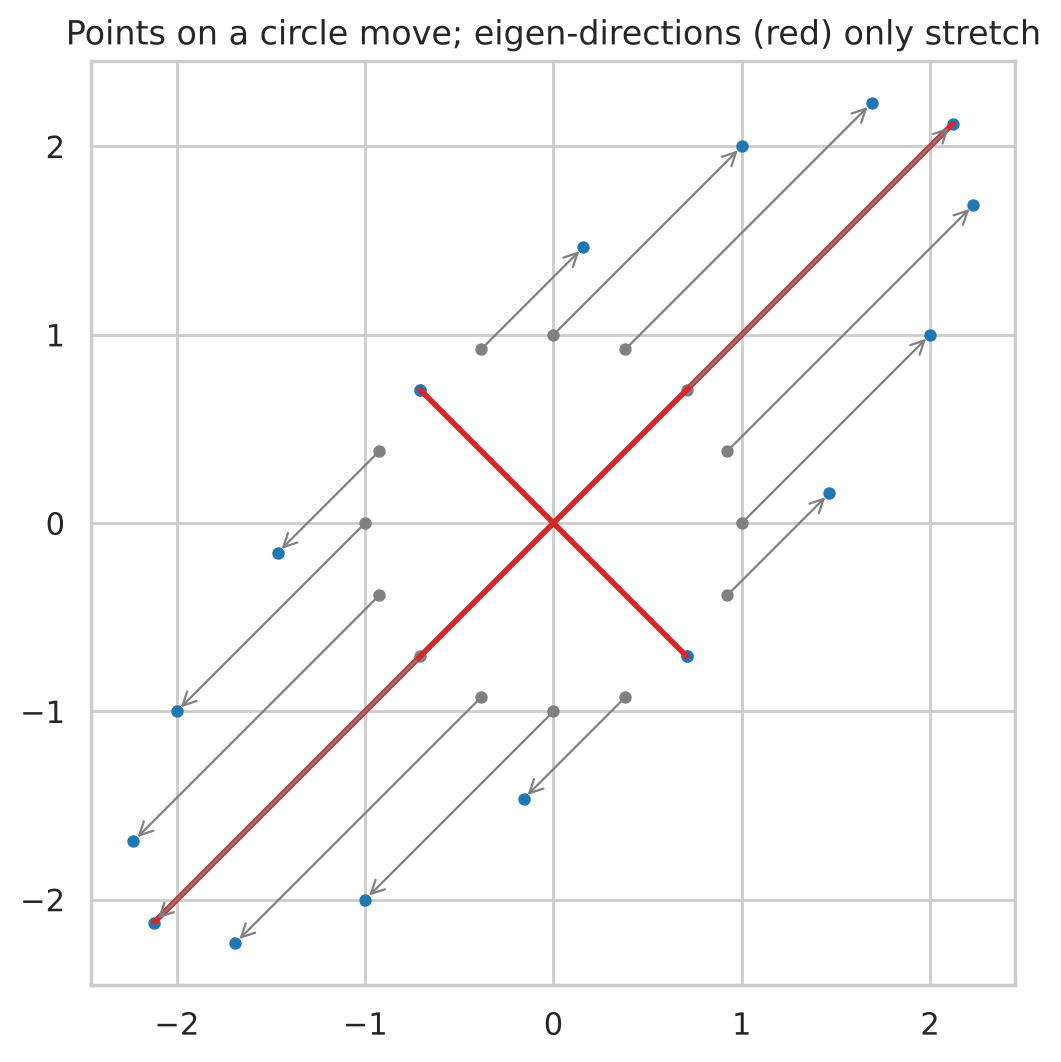

In [13]:
angles = np.linspace(0, 2 * np.pi, 16, endpoint=False)
circle = np.vstack([np.cos(angles), np.sin(angles)])
moved = A @ circle

fig, ax = plt.subplots(figsize=(6, 6))
for i in range(circle.shape[1]):
    ax.annotate("", xy=moved[:, i], xytext=circle[:, i],
                arrowprops=dict(arrowstyle="->", color="gray", lw=0.8))
ax.scatter(*circle, s=12, color="gray")
ax.scatter(*moved, s=12, color="tab:blue")
for lam, vec in zip(eigenvalues, eigenvectors.T):
    ax.plot([-lam * vec[0], lam * vec[0]], [-lam * vec[1], lam * vec[1]], color="tab:red", linewidth=2)
ax.set_aspect("equal")
ax.set_title("Points on a circle move; eigen-directions (red) only stretch")
plt.show()

<div dir="rtl">

دایره به یک بیضی تبدیل شد. محورهای بیضی دقیقاً همان بردارهای ویژه‌اند: در جهت $(1, 1)$ سه برابر کشیده شده و در جهت $(1, -1)$ بدون تغییر مانده است.

## ۸. کاربرد: PCA از صفر

**تحلیل مؤلفه‌های اصلی (PCA)** داده‌ی چندبعدی را به ابعاد کمتری فشرده می‌کند و تا جای ممکن اطلاعات (واریانس) را حفظ می‌کند. ایده: جهت‌هایی را پیدا کن که داده بیشترین پراکندگی را در آن‌ها دارد. این جهت‌ها **بردارهای ویژه‌ی ماتریس کوواریانس** هستند و مقدار ویژه‌ی هر کدام، میزان واریانس در آن جهت است.

مراحل:

1. استانداردسازی ستون‌ها (میانگین صفر، انحراف معیار یک)
2. محاسبه‌ی ماتریس کوواریانس: $C = \frac{1}{n-1} Z^\top Z$
3. محاسبه‌ی مقادیر و بردارهای ویژه‌ی $C$ و مرتب‌سازی نزولی آن‌ها
4. تصویر داده روی چند بردار ویژه‌ی اول: $Z W$

</div>

In [14]:
features = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
data = penguins[features].values

Z = (data - data.mean(axis=0)) / data.std(axis=0, ddof=1)        # 1. standardise
C = Z.T @ Z / (len(Z) - 1)                                        # 2. covariance matrix
eigvals, eigvecs = np.linalg.eigh(C)                              # 3. eigh: for symmetric matrices
order = np.argsort(eigvals)[::-1]
eigvals, eigvecs = eigvals[order], eigvecs[:, order]
explained = eigvals / eigvals.sum()

print("explained variance ratio:", explained.round(3))
print("first two components explain", f"{explained[:2].sum():.1%}", "of the variance")
pd.DataFrame(eigvecs[:, :2], index=features, columns=["PC1", "PC2"]).round(2)

explained variance ratio: [0.686 0.195 0.092 0.027]
first two components explain 88.1% of the variance


,PC1,PC2
bill_length_mm,-0.45,0.60
bill_depth_mm,0.40,0.80
flipper_length_mm,-0.58,0.01
body_mass_g,-0.55,0.08


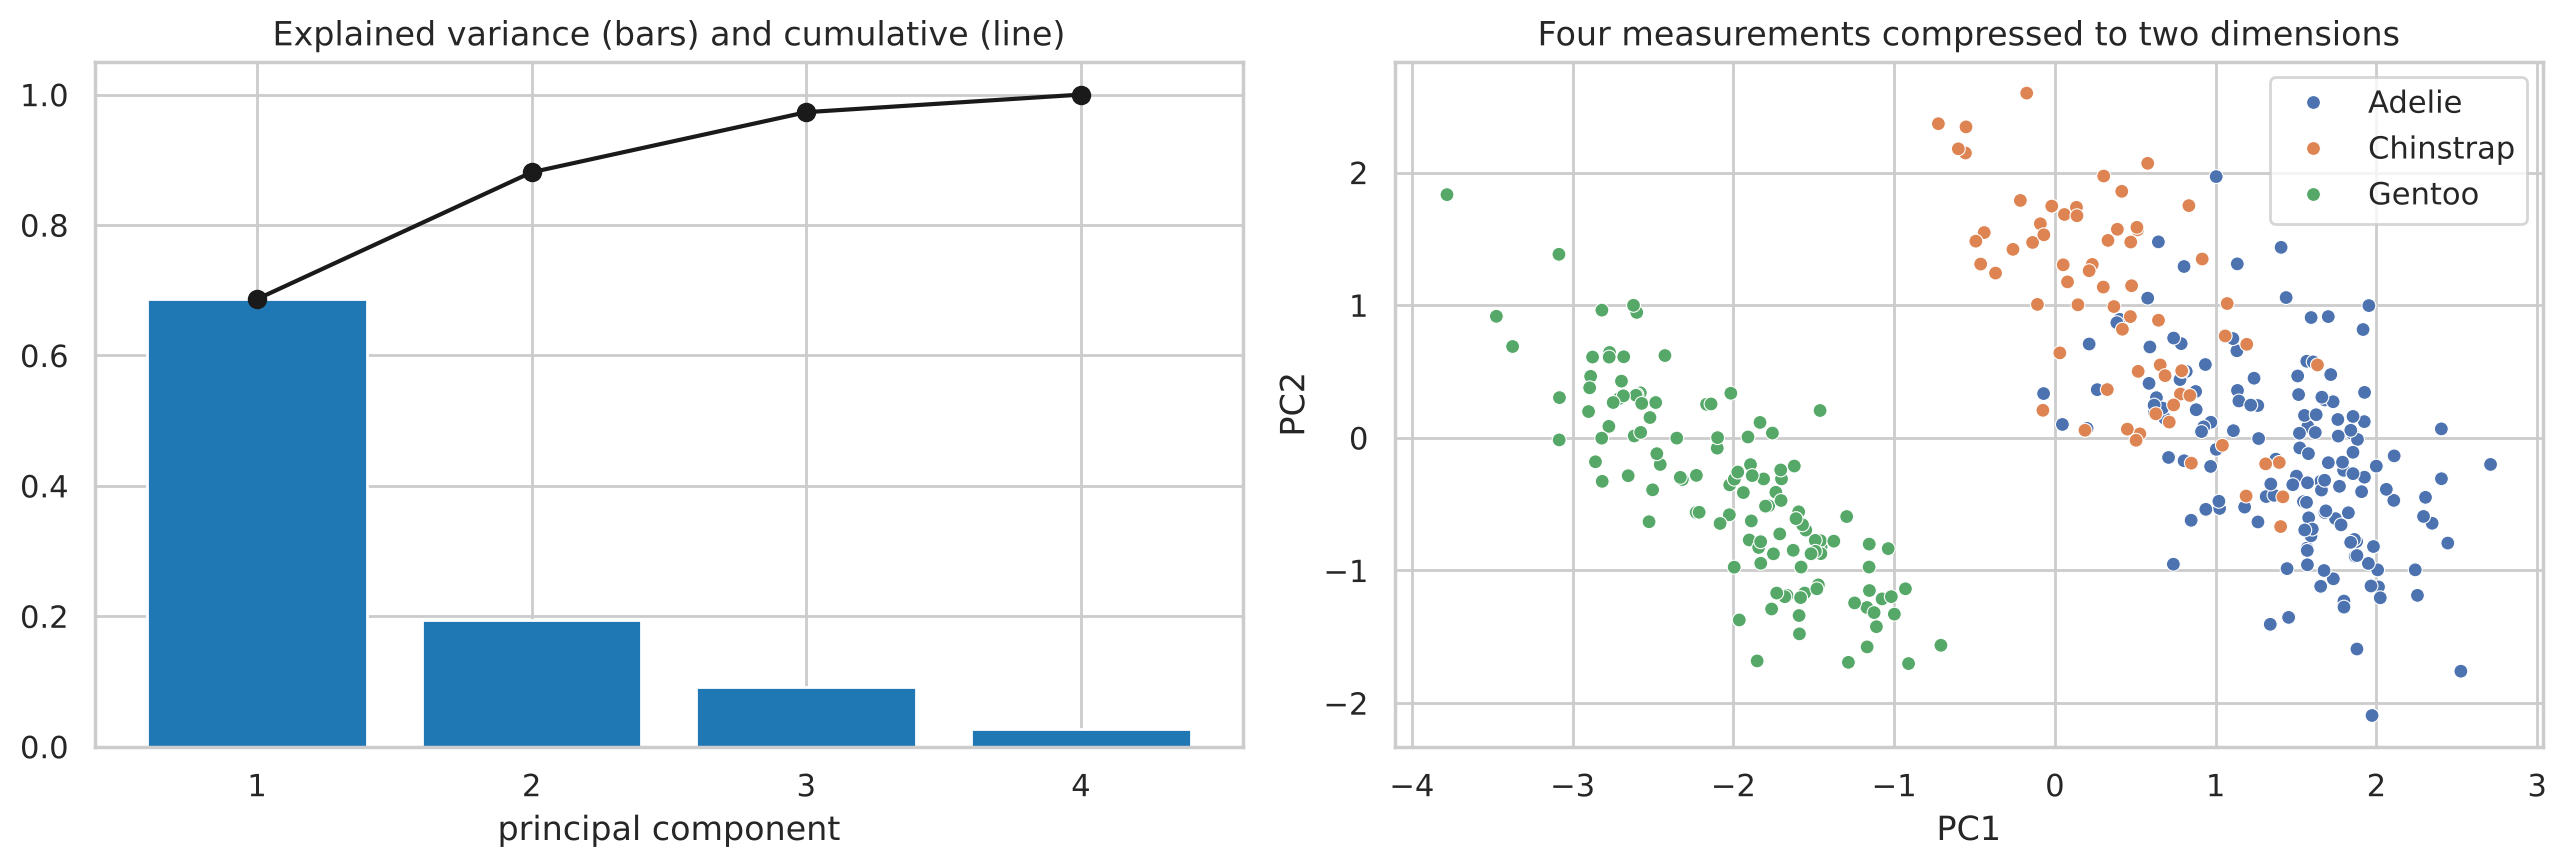

In [15]:
scores = Z @ eigvecs[:, :2]                                       # 4. project to 2-D

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(range(1, 5), explained, color="tab:blue")
axes[0].plot(range(1, 5), np.cumsum(explained), "ko-")
axes[0].set_xticks(range(1, 5))
axes[0].set_xlabel("principal component")
axes[0].set_title("Explained variance (bars) and cumulative (line)")
sns.scatterplot(x=scores[:, 0], y=scores[:, 1], hue=penguins["species"].values, ax=axes[1], s=25)
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")
axes[1].set_title("Four measurements compressed to two dimensions")
plt.tight_layout()
plt.show()

<div dir="rtl">

- مؤلفه‌ی اول حدود ۶۹٪ واریانس را توضیح می‌دهد. در ضرایبش طول باله، وزن و طول منقار هم‌علامت‌اند و عمق منقار علامت مخالف دارد؛ عملاً یک شاخص «اندازه‌ی بدن» است. (علامت کل یک بردار ویژه دلخواه است؛ $v$ و $-v$ هر دو بردار ویژه‌اند.)
- با فقط دو بُعد، حدود ۸۸٪ اطلاعات حفظ شده و سه گونه تقریباً از هم جدا شده‌اند، بدون اینکه گونه را به الگوریتم داده باشیم.
- در ترم بعد همین کار را با `sklearn.decomposition.PCA` انجام می‌دهیم که درون خودش از تجزیه‌ی SVD استفاده می‌کند؛ نتیجه یکسان است.

## جمع‌بندی

| مفهوم | در علم داده |
|---|---|
| بردار | یک مشاهده (یک سطر) |
| ضرب داخلی و شباهت کسینوسی | شباهت متن‌ها، توصیه‌گرها، جست‌وجوی معنایی |
| ضرب ماتریسی | پیش‌بینی مدل خطی، لایه‌های شبکه‌ی عصبی |
| دترمینان صفر | ویژگی‌های تکراری (هم‌خطی) |
| کمترین مربعات | رگرسیون خطی |
| مقدار و بردار ویژه | PCA، کاهش ابعاد |

## تمرین

1. شباهت کسینوسی بردار `[1, 2, 3]` با `[2, 4, 6]` و با `[-1, -2, -3]` را حساب کنید و توضیح دهید.
2. ماتریس دوران ۹۰ درجه را بنویسید و نشان دهید که چهار بار اعمال آن، ماتریس همانی می‌دهد.
3. یک دستگاه سه معادله و سه مجهول بنویسید و با `np.linalg.solve` حل کنید. ضرایب را طوری انتخاب کنید که دستگاه جواب نداشته باشد؛ چه خطایی می‌گیرید؟
4. با کمترین مربعات، `body_mass_g` را از **هر چهار** ویژگی عددی پنگوئن پیش‌بینی کنید. $R^2$ چقدر بهتر شد؟
5. PCA را بدون استانداردسازی (فقط با کم کردن میانگین) تکرار کنید. چرا تقریباً همه‌ی واریانس در مؤلفه‌ی اول قرار می‌گیرد؟ (راهنما: واحد `body_mass_g`)

</div>